# 3. Huấn luyện và Đánh giá Mô hình (Baselines Mốc 2 & Mô hình Đề xuất Mốc 3)

Notebook này được chia thành các bước độc lập, có cơ chế lưu cache để chạy tuần tự (`Run All`) nhanh chóng theo đúng lộ trình từ mô hình cơ sở đến mô hình đa phương thức đề xuất, nghiên cứu loại bỏ và theo dõi huấn luyện:
1. **Thiết lập môi trường & đường dẫn dữ liệu**
2. **Phân chia tập dữ liệu (`Train` / `Validation` / `Test`) & Cách ly (`Quarantine`)**
3. **Khởi tạo `Dataset` & `DataLoader`**
4. **Xây dựng & Đánh giá 2 Mô hình Baseline (Mốc 2 — Chỉ dùng tín hiệu ECG: `Logistic Regression` & `ResNet1DClassifier`)**
5. **Khởi tạo Mô hình đề xuất (Mốc 3): `InceptionBiGRUClassifier` (ECG + Clinical Late Fusion `[age_z, sex]`)**
6. **Huấn luyện Mô hình đề xuất (Training Loop + TensorBoard `SummaryWriter`)**
7. **Nạp Best Checkpoint & Đánh giá Mô hình đề xuất trên tập Validation (Fold 9)**
8. **Đánh giá Mô hình đề xuất trên tập Test (Fold 10): Trước ($	au = 0.5$) và Sau khi tối ưu ngưỡng (Threshold Tuning)**
9. **Nghiên cứu loại bỏ (`Exact-Parent Ablation Study` — Bảng 11A, 11B, 11C theo Tassaddiq et al., 2026)**
10. **Theo dõi huấn luyện (`TensorBoard SummaryWriter`), Đồ thị `Learning Curves` & Biểu đồ So sánh Kiến trúc**

## 1. Thiết lập môi trường & Đường dẫn dữ liệu

Cố định hạt giống ngẫu nhiên (`SEED = 42`), kiểm tra thiết bị tính toán (CPU/CUDA GPU) và định vị các đường dẫn dữ liệu đã tiền xử lý cùng thư mục lưu checkpoint.

In [1]:
from pathlib import Path
import ast
import sys

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

current_dir = Path.cwd().resolve()
project_root = next(
    (path for path in (current_dir, *current_dir.parents)
     if (path / 'data' / 'processed' / 'ptbxl_recordwise_leadwise_zscore_500hz.npy').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Không tìm thấy thư mục gốc chứa data/processed/. Hãy chạy 2_preprocessing.ipynb trước.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data import PTBXLMultiModalDataset, SUPERCLASSES, assert_patient_disjoint
from src.engine import (
    DEFAULT_RECALL_BETAS,
    evaluate_predictions,
    find_optimal_thresholds,
    run_epoch,
)
from src.models import InceptionBiGRUClassifier, ResNet1DClassifier

data_dir = project_root / 'data'
processed_dir = data_dir / 'processed'
signal_path = processed_dir / 'ptbxl_recordwise_leadwise_zscore_500hz.npy'
signal_index_path = processed_dir / 'ptbxl_recordwise_leadwise_zscore_500hz_index.csv'
clinical_path = processed_dir / 'ptbxl_clinical_features_age_zscore_sex_binary.csv'
checkpoint_dir = project_root / 'models' / 'checkpoints'
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = checkpoint_dir / 'inception_bigru_best.pt'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Project root :', project_root)
print('Device       :', device)
if device.type == 'cuda':
    print('GPU          :', torch.cuda.get_device_name(0))
print('Checkpoint   :', checkpoint_path, f'(exists={checkpoint_path.is_file()})')

Project root : C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg
Device       : cuda
GPU          : NVIDIA GeForce RTX 3050 Laptop GPU
Checkpoint   : C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\models\checkpoints\inception_bigru_best.pt (exists=True)


## 2. Phân chia tập dữ liệu & Cách ly bệnh nhân ngoại lệ (Quarantine)

- **Fold 1–8**: `Train` | **Fold 9**: `Validation` | **Fold 10**: `Test`
- Loại bỏ toàn bộ bệnh nhân có bản ghi chỉ chứa mã `form/rhythm` không ánh xạ vào 5 superclass khỏi cả 3 tập.
- Kiểm tra nghiêm ngặt **Zero Data Leakage** cấp độ bệnh nhân (`assert_patient_disjoint`).

In [2]:
metadata = pd.read_csv(data_dir / 'ptbxl_database.csv', encoding='latin-1')
scp_statements = pd.read_csv(data_dir / 'scp_statements.csv', index_col=0)
signal_index = pd.read_csv(signal_index_path)
clinical_features = pd.read_csv(clinical_path)

diagnostic = scp_statements.loc[scp_statements['diagnostic'].eq(1.0)]
superclass_lookup = {
    str(code): str(row['diagnostic_class'])
    for code, row in diagnostic.iterrows()
    if pd.notna(row.get('diagnostic_class')) and str(row['diagnostic_class']) in SUPERCLASSES
}
form_rhythm_codes = {
    str(code) for code, row in scp_statements.iterrows()
    if row.get('form') == 1.0 or row.get('rhythm') == 1.0
}

def parse_scp_codes(value):
    if pd.isna(value):
        return {}
    try:
        parsed = ast.literal_eval(value)
    except (TypeError, ValueError, SyntaxError):
        return {}
    return parsed if isinstance(parsed, dict) else {}

def is_form_rhythm_only_unmapped(value):
    codes = set(parse_scp_codes(value))
    return bool(codes) and codes.issubset(form_rhythm_codes) and codes.isdisjoint(superclass_lookup)

review_patient_ids = set(
    metadata.loc[metadata['scp_codes'].map(is_form_rhythm_only_unmapped), 'patient_id']
)
records = signal_index.merge(
    clinical_features, on='ecg_id', how='inner', validate='one_to_one', suffixes=('', '_clinical')
)
eligible = records.loc[~records['patient_id'].isin(review_patient_ids)].copy()

train_records = eligible.loc[eligible['strat_fold'].isin(range(1, 9))].copy()
validation_records = eligible.loc[eligible['strat_fold'].eq(9)].copy()
test_records = eligible.loc[eligible['strat_fold'].eq(10)].copy()
assert_patient_disjoint(train_records, validation_records, test_records)

print(f'Quarantined patients : {len(review_patient_ids):,}')
print(f'Train records        : {len(train_records):,} (folds 1-8)')
print(f'Validation records   : {len(validation_records):,} (fold 9)')
print(f'Test records         : {len(test_records):,} (fold 10)')
print('Patient overlap audit: PASSED')

Quarantined patients : 324
Train records        : 17,005 (folds 1-8)
Validation records   : 2,150 (fold 9)
Test records         : 2,150 (fold 10)
Patient overlap audit: PASSED


## 3. Khởi tạo `Dataset` & `DataLoader`

Khởi tạo các đối tượng `PTBXLMultiModalDataset` đọc dữ liệu ECG qua `mmap` kết hợp đặc trưng lâm sàng `[age_z, sex]`, tạo `DataLoader` cho 3 tập và kiểm tra kích thước tensor đầu vào của một batch mẫu.

In [3]:
BATCH_SIZE = 64

train_dataset = PTBXLMultiModalDataset(
    train_records, signal_path, signal_index_path, clinical_path, expected_folds=set(range(1, 9))
)
validation_dataset = PTBXLMultiModalDataset(
    validation_records, signal_path, signal_index_path, clinical_path, expected_folds={9}
)
test_dataset = PTBXLMultiModalDataset(
    test_records, signal_path, signal_index_path, clinical_path, expected_folds={10}
)

loader_options = {
    'batch_size': BATCH_SIZE,
    'num_workers': 0,
    'pin_memory': device.type == 'cuda',
}
train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
validation_loader = DataLoader(validation_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

sample_batch = next(iter(validation_loader))
print('ECG batch shape     :', tuple(sample_batch['ecg'].shape), sample_batch['ecg'].dtype)
print('Clinical batch shape:', tuple(sample_batch['clinical'].shape), '| sample:', sample_batch['clinical'][0].tolist())
print('Target batch shape  :', tuple(sample_batch['target'].shape), '| classes:', SUPERCLASSES)

ECG batch shape     : (64, 12, 5000) torch.float32
Clinical batch shape: (64, 2) | sample: [-0.6826261878013611, 0.0]
Target batch shape  : (64, 5) | classes: ('NORM', 'MI', 'STTC', 'CD', 'HYP')


## 4. Baseline Models (Mốc 2 — Chỉ dùng tín hiệu ECG: `Logistic Regression` & `ResNet1D`)

Để đối chứng và chứng minh hiệu quả của kiến trúc đề xuất ở Mốc 3 (`InceptionTime 1D + Bidirectional GRU + Attention Pooling + Clinical Late Fusion [age_z, sex]`), nhóm xây dựng **2 mô hình Baseline ở Mốc 2 chỉ sử dụng tín hiệu ECG (`ECG-only`, không dùng 2 đặc trưng lâm sàng `[age_z, sex]`)**:
1. **Baseline 1 (`OneVsRest(LogisticRegression)` — Học máy cổ điển, ECG-only):** Sử dụng `84` đặc trưng thống kê hình thái học trên 12 chuyển đạo (`12 chuyển đạo × 7 thống kê: min, max, q10, median, q90, mean_abs, mean_abs_diff`), chuẩn hóa bằng `StandardScaler` chỉ fit trên tập Train (`Fold 1–8`).
2. **Baseline 2 (`ResNet1DClassifier` — Học sâu tích chập 1D chuẩn, ECG-only):** Mạng tích chập phần dư 1 chiều (`3 khối ResidualBlock1D + AdaptiveAvgPool1d`, `198,213` tham số) huấn luyện trực tiếp trên sóng ECG thô `(12, 5000)` nhưng chưa có bộ mã hóa đa tỷ lệ `InceptionTime`, chưa có `Bidirectional GRU + Attention` và chưa kết hợp đặc trưng lâm sàng `[age_z, sex]`.

In [4]:
# Baseline 1 (Logistic Regression, ECG-only) & Baseline 2 (ResNet1DClassifier, ECG-only)
import json
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from src.models import ResNet1DClassifier

FORCE_RETRAIN_BASELINES = False
baselines_cache_path = checkpoint_dir / "baselines_eval_cache.json"
resnet_ckpt_path = checkpoint_dir / "resnet1d_ecg_baseline_best.pt"

if baselines_cache_path.is_file() and not FORCE_RETRAIN_BASELINES:
    print(f"Đang nạp kết quả Baseline 1 & Baseline 2 từ cache: {baselines_cache_path.name}")
    _b_cache = json.loads(baselines_cache_path.read_text(encoding="utf-8"))
    b1_val_metrics = _b_cache["baseline1_logreg"]["val"]
    b1_test_metrics = _b_cache["baseline1_logreg"]["test"]
    b2_val_metrics = _b_cache["baseline2_resnet1d"]["val"]
    b2_test_metrics = _b_cache["baseline2_resnet1d"]["test"]
    b2_params = int(_b_cache["baseline2_resnet1d"]["params"])
    b2_best_epoch = int(_b_cache["baseline2_resnet1d"]["epoch"])
else:
    def extract_ecg_only_features(part_df: pd.DataFrame, batch_size: int = 2048) -> np.ndarray:
        positions = part_df["array_position"].to_numpy(dtype=np.int64)
        signals_mmap = np.load(signal_path, mmap_mode="r")
        n = len(positions)
        feats = np.empty((n, 12 * 7), dtype=np.float32)
        for start in range(0, n, batch_size):
            end = min(start + batch_size, n)
            batch = np.asarray(signals_mmap[positions[start:end]], dtype=np.float32)
            f_min = batch.min(axis=1)
            f_max = batch.max(axis=1)
            q10, q50, q90 = np.percentile(batch, [10, 50, 90], axis=1)
            f_abs = np.abs(batch).mean(axis=1)
            f_diff = np.abs(np.diff(batch, axis=1)).mean(axis=1)
            feats[start:end] = np.concatenate([f_min, f_max, q10, q50, q90, f_abs, f_diff], axis=1)
        return feats

    X_train_ecg = extract_ecg_only_features(train_records)
    X_val_ecg = extract_ecg_only_features(validation_records)
    X_test_ecg = extract_ecg_only_features(test_records)

    y_train_base = train_dataset.targets
    y_val_base = validation_dataset.targets
    y_test_base = test_dataset.targets

    ecg_scaler = StandardScaler()
    X_train_ecg_s = ecg_scaler.fit_transform(X_train_ecg)
    X_val_ecg_s = ecg_scaler.transform(X_val_ecg)
    X_test_ecg_s = ecg_scaler.transform(X_test_ecg)

    baseline1_logreg = OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=SEED))
    baseline1_logreg.fit(X_train_ecg_s, y_train_base)
    b1_val_metrics = evaluate_predictions(y_val_base, baseline1_logreg.predict_proba(X_val_ecg_s), detailed_metrics=True, threshold=0.5)
    b1_test_metrics = evaluate_predictions(y_test_base, baseline1_logreg.predict_proba(X_test_ecg_s), detailed_metrics=True, threshold=0.5)

    resnet_baseline = ResNet1DClassifier().to(device)
    resnet_ckpt = torch.load(resnet_ckpt_path, map_location=device, weights_only=True)
    resnet_baseline.load_state_dict(resnet_ckpt["model_state_dict"])
    b2_params = sum(p.numel() for p in resnet_baseline.parameters() if p.requires_grad)
    b2_best_epoch = int(resnet_ckpt["epoch"])
    b2_val_metrics = run_epoch(resnet_baseline, validation_loader, device, optimizer=None, amp=True, detailed_metrics=True, threshold=0.5)
    b2_test_metrics = run_epoch(resnet_baseline, test_loader, device, optimizer=None, amp=True, detailed_metrics=True, threshold=0.5)
    baselines_cache_path.write_text(json.dumps({
        "baseline1_logreg": {"val": b1_val_metrics, "test": b1_test_metrics},
        "baseline2_resnet1d": {"epoch": b2_best_epoch, "params": b2_params, "val": b2_val_metrics, "test": b2_test_metrics},
    }, indent=2, ensure_ascii=False), encoding="utf-8")

for title, val_m, test_m in [
    ("BASELINE 1 (MỐC 2): MULTI-LABEL LOGISTIC REGRESSION (ECG-ONLY, 84 FEATURES)", b1_val_metrics, b1_test_metrics),
    (f"BASELINE 2 (MỐC 2): 1D RESNET CLASSIFIER (ECG-ONLY, {b2_params:,} PARAMS, BEST EPOCH {b2_best_epoch})", b2_val_metrics, b2_test_metrics),
]:
    print(f"=== {title} ===")
    print(
        f"[Validation - Fold 9 (n={len(validation_dataset)}, threshold=0.5)] "
        f"Macro AUROC: {val_m['macro_auroc']:.4f} | Macro AUPRC: {val_m['macro_auprc']:.4f} | "
        f"Macro F1: {val_m['macro_f1']:.4f} | Macro Precision: {val_m['macro_precision']:.4f} | "
        f"Macro Recall: {val_m['macro_recall']:.4f} | Macro Acc: {val_m['macro_accuracy']:.4f} | "
        f"Subset Acc: {val_m['subset_accuracy']:.4f}"
    )
    print(
        f"[Test - Fold 10 (n={len(test_dataset)}, threshold=0.5)]       "
        f"Macro AUROC: {test_m['macro_auroc']:.4f} | Macro AUPRC: {test_m['macro_auprc']:.4f} | "
        f"Macro F1: {test_m['macro_f1']:.4f} | Macro Precision: {test_m['macro_precision']:.4f} | "
        f"Macro Recall: {test_m['macro_recall']:.4f} | Macro Acc: {test_m['macro_accuracy']:.4f} | "
        f"Subset Acc: {test_m['subset_accuracy']:.4f}"
    )
    print(f"{'Label':<8} {'AUROC':>8} {'AUPRC':>8} {'Precision':>10} {'Recall':>8} {'F1':>8} {'Accuracy':>10}")
    for lbl in SUPERCLASSES:
        pm = test_m["per_label"][lbl]
        print(
            f"{lbl:<8} {pm['auroc']:>8.4f} {pm['auprc']:>8.4f} {pm['precision']:>10.4f} "
            f"{pm['recall']:>8.4f} {pm['f1']:>8.4f} {pm['accuracy']:>10.4f}"
        )
    print()

Đang nạp kết quả Baseline 1 & Baseline 2 từ cache: baselines_eval_cache.json
=== BASELINE 1 (MỐC 2): MULTI-LABEL LOGISTIC REGRESSION (ECG-ONLY, 84 FEATURES) ===
[Validation - Fold 9 (n=2150, threshold=0.5)] Macro AUROC: 0.8285 | Macro AUPRC: 0.6232 | Macro F1: 0.5111 | Macro Precision: 0.7009 | Macro Recall: 0.4482 | Macro Acc: 0.8269 | Subset Acc: 0.4521
[Test - Fold 10 (n=2150, threshold=0.5)]       Macro AUROC: 0.8207 | Macro AUPRC: 0.6164 | Macro F1: 0.4901 | Macro Precision: 0.6888 | Macro Recall: 0.4220 | Macro Acc: 0.8208 | Subset Acc: 0.4414
Label       AUROC    AUPRC  Precision   Recall       F1   Accuracy
NORM       0.8598   0.8108     0.7306   0.7748   0.7520     0.7721
MI         0.7831   0.5572     0.6552   0.3115   0.4222     0.7823
STTC       0.8691   0.6730     0.7077   0.4981   0.5847     0.8288
CD         0.8185   0.6771     0.7508   0.4575   0.5686     0.8405
HYP        0.7731   0.3642     0.6000   0.0684   0.1229     0.8805

=== BASELINE 2 (MỐC 2): 1D RESNET CLASSIF

## 5. Khởi tạo Mô hình đề xuất (Mốc 3): `InceptionBiGRUClassifier` (ECG + Clinical Late Fusion)

Khởi tạo mô hình đa phương thức kết hợp `InceptionTime 1D` (`branch_channels=32`), `Bidirectional GRU` (`gru_hidden_size=96`, `gru_layers=2`), `Attention Pooling` và nhánh lâm sàng `[age_z, sex]` (`16 chiều`), sau đó kiểm tra forward pass.

In [5]:
model = InceptionBiGRUClassifier().to(device)
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {parameter_count:,}')

model.eval()
with torch.inference_mode():
    sample_logits = model(sample_batch['ecg'].to(device), sample_batch['clinical'].to(device))
    sample_loss = torch.nn.BCEWithLogitsLoss()(sample_logits, sample_batch['target'].to(device))
print('Forward check       : logits shape =', tuple(sample_logits.shape), f'| initial BCE loss = {float(sample_loss):.4f}')

Trainable parameters: 905,158
Forward check       : logits shape = (64, 5) | initial BCE loss = 0.8398


## 6. Huấn luyện Mô hình đề xuất (Training Loop)

- Mặc định `FORCE_RETRAIN = False`: Nếu tệp checkpoint `models/checkpoints/inception_bigru_best.pt` **đã tồn tại**, cell này sẽ bỏ qua bước train để tiết kiệm thời gian và giữ nguyên trọng số đã huấn luyện.
- Đổi `FORCE_RETRAIN = True` nếu bạn muốn huấn luyện lại từ đầu trên GPU.

In [6]:
from torch.utils.tensorboard import SummaryWriter

FORCE_RETRAIN = False
EPOCHS = 14
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
tb_log_dir = project_root / 'runs' / 'ptbxl_m3'

if checkpoint_path.is_file() and not FORCE_RETRAIN:
    print(f'Đã tìm thấy checkpoint tại: {checkpoint_path}')
    print('Bỏ qua bước huấn luyện (đặt FORCE_RETRAIN = True nếu muốn train lại từ đầu).')
else:
    if device.type != 'cuda':
        raise RuntimeError('Huấn luyện đầy đủ yêu cầu GPU (CUDA). Hãy kiểm tra torch.cuda.is_available().')

    writer = SummaryWriter(log_dir=str(tb_log_dir / 'full_proposed_model'))
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    best_validation_auprc = float('-inf')
    best_epoch = None
    train_history = []

    for epoch in range(1, EPOCHS + 1):
        train_metrics = run_epoch(model, train_loader, device, optimizer=optimizer, amp=True)
        val_metrics = run_epoch(model, validation_loader, device, amp=True)
        score = val_metrics['macro_auprc']
        writer.add_scalar('Loss/train', train_metrics['loss'], epoch)
        writer.add_scalar('Loss/val', val_metrics['loss'], epoch)
        writer.add_scalar('Metrics/val_macro_auroc', val_metrics['macro_auroc'], epoch)
        writer.add_scalar('Metrics/val_macro_auprc', score, epoch)
        train_history.append({
            'epoch': epoch, 'train_loss': float(train_metrics['loss']),
            'val_loss': float(val_metrics['loss']),
            'val_macro_auroc': float(val_metrics['macro_auroc']),
            'val_macro_auprc': float(score),
        })
        print(
            f'Epoch {epoch:02d}/{EPOCHS} | '
            f'train loss: {train_metrics["loss"]:.4f} | '
            f'val loss: {val_metrics["loss"]:.4f} | '
            f'val macro AUPRC: {score:.6f}'
        )
        if score is not None and score > best_validation_auprc:
            best_validation_auprc = score
            best_epoch = epoch
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'validation_macro_auprc': score,
                'clinical_feature_order': ['age_z', 'sex'],
                'labels': list(SUPERCLASSES),
                'history': train_history,
            }, checkpoint_path)
    writer.close()

    if best_epoch is None:
        raise RuntimeError('Không chọn được checkpoint nào.')
    print(f'\nHoàn tất huấn luyện! Best epoch: {best_epoch} (val macro AUPRC = {best_validation_auprc:.6f})')

Đã tìm thấy checkpoint tại: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\models\checkpoints\inception_bigru_best.pt
Bỏ qua bước huấn luyện (đặt FORCE_RETRAIN = True nếu muốn train lại từ đầu).


## 7. Nạp Best Checkpoint & Đánh giá Mô hình đề xuất trên tập Validation (Fold 9)

- Nạp checkpoint tốt nhất vào `model` và đánh giá trên tập **Validation (Fold 9)**.
- Tìm ngưỡng tối ưu $F_1$-score ($\beta = 1.0$) trên tập Validation cho từng nhãn (riêng nhãn **`CD` giữ nguyên ngưỡng `0.5`**) và in kết quả **Trước** vs. **Sau** khi tối ưu ngưỡng.

In [7]:
if not checkpoint_path.is_file():
    raise FileNotFoundError(f'Không tìm thấy checkpoint: {checkpoint_path}. Hãy chạy huấn luyện ở mục 6 trước.')

checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
if checkpoint.get('labels') != list(SUPERCLASSES):
    raise ValueError('Thứ tự nhãn trong checkpoint không khớp với SUPERCLASSES.')
if checkpoint.get('clinical_feature_order') != ['age_z', 'sex']:
    raise ValueError('Thứ tự đặc trưng lâm sàng trong checkpoint không khớp với [age_z, sex].')

model.load_state_dict(checkpoint['model_state_dict'])
DEFAULT_THRESHOLD = 0.5
ablation_cache_path = checkpoint_dir / "ablation_results_cache.json"

if ablation_cache_path.is_file() and not FORCE_RETRAIN:
    _full_cache = json.loads(ablation_cache_path.read_text(encoding="utf-8"))["full_model"]
    val_outputs = _full_cache["val_at_05"]
    tuned_thresholds = _full_cache["thresholds_tuned"]
    val_tuned_metrics = _full_cache["val_at_tuned"]
else:
    val_outputs = run_epoch(
        model, validation_loader, device, amp=True,
        detailed_metrics=True, threshold=DEFAULT_THRESHOLD, return_predictions=True,
    )
    tuned_thresholds = find_optimal_thresholds(
        val_outputs['targets'],
        val_outputs['probabilities'],
        betas=1.0,
    )
    tuned_thresholds['CD'] = 0.5
    val_tuned_metrics = evaluate_predictions(
        val_outputs['targets'],
        val_outputs['probabilities'],
        loss=val_outputs['loss'],
        detailed_metrics=True,
        threshold=tuned_thresholds,
    )

print(f'Loaded checkpoint from Epoch {checkpoint["epoch"]} (saved val macro AUPRC = {checkpoint["validation_macro_auprc"]:.4f})')

val_default_table = pd.DataFrame.from_dict(val_outputs['per_label'], orient='index')
val_default_table.index.name = 'Superclass'
print(f'\n=== [VALIDATION] TRƯỚC KHI TỐI ƯU NGƯỠNG (THRESHOLD CỐ ĐỊNH = {DEFAULT_THRESHOLD:.1f}) ===')
print(val_default_table.to_string(float_format=lambda v: f'{v:.4f}'))
print('Validation Macro Metrics (Trước khi tối ưu ngưỡng):')
for metric in ('macro_auroc', 'macro_auprc', 'macro_precision', 'macro_recall', 'macro_f1', 'macro_accuracy', 'subset_accuracy'):
    print(f'  {metric:<16}: {val_outputs[metric]:.4f}')

val_tuned_table = pd.DataFrame.from_dict(val_tuned_metrics['per_label'], orient='index')
val_tuned_table.index.name = 'Superclass'
print('\n=== [VALIDATION] SAU KHI TỐI ƯU NGƯỠNG (KỊCH BẢN B, RIÊNG CD = 0.5) ===')
print('Bộ ngưỡng tìm được:', tuned_thresholds)
print(val_tuned_table.to_string(float_format=lambda v: f'{v:.4f}'))
print('Validation Macro Metrics (Sau khi tối ưu ngưỡng):')
for metric in ('macro_auroc', 'macro_auprc', 'macro_precision', 'macro_recall', 'macro_f1', 'macro_accuracy', 'subset_accuracy'):
    print(f'  {metric:<16}: {val_tuned_metrics[metric]:.4f}')

Loaded checkpoint from Epoch 12 (saved val macro AUPRC = 0.7634)

=== [VALIDATION] TRƯỚC KHI TỐI ƯU NGƯỠNG (THRESHOLD CỐ ĐỊNH = 0.5) ===
            auroc  auprc  precision  recall     f1  accuracy
Superclass                                                  
NORM       0.9364 0.9070     0.7938  0.9152 0.8502    0.8567
MI         0.9239 0.8338     0.8817  0.5764 0.6971    0.8735
STTC       0.9250 0.7761     0.7125  0.7702 0.7403    0.8665
CD         0.9333 0.8534     0.7695  0.7742 0.7719    0.8944
HYP        0.8126 0.4468     0.5736  0.2731 0.3700    0.8828
Validation Macro Metrics (Trước khi tối ưu ngưỡng):
  macro_auroc     : 0.9062
  macro_auprc     : 0.7634
  macro_precision : 0.7462
  macro_recall    : 0.6618
  macro_f1        : 0.6859
  macro_accuracy  : 0.8748
  subset_accuracy : 0.6000

=== [VALIDATION] SAU KHI TỐI ƯU NGƯỠNG (KỊCH BẢN B, RIÊNG CD = 0.5) ===
Bộ ngưỡng tìm được: {'NORM': 0.645, 'MI': 0.145, 'STTC': 0.495, 'CD': 0.5, 'HYP': 0.27}
            auroc  auprc  threshol

## 8. Đánh giá Mô hình đề xuất trên tập Test (Fold 10): Trước và Sau khi tối ưu ngưỡng

Chạy mô hình đề xuất một lần trên tập **Test (Fold 10)** và in đối chiếu kết quả:
1. **Trước khi tối ưu ngưỡng:** Dùng ngưỡng mặc định $\tau = 0.5$ cho cả 5 nhãn.
2. **Sau khi tối ưu ngưỡng:** Áp dụng bộ ngưỡng `tuned_thresholds` tìm được từ tập Validation ở mục 7 (riêng `CD = 0.5`).

In [8]:
if ablation_cache_path.is_file() and not FORCE_RETRAIN:
    _full_cache = json.loads(ablation_cache_path.read_text(encoding="utf-8"))["full_model"]
    _t05 = _full_cache["test_at_05"]
    _ttuned = _full_cache["test_at_tuned"]
    test_outputs = {**_t05, "subset_accuracy": _t05["exact_match"]}
    test_tuned_metrics = {**_ttuned, "subset_accuracy": _ttuned["exact_match"]}
else:
    test_outputs = run_epoch(
        model, test_loader, device, amp=True,
        detailed_metrics=True, threshold=DEFAULT_THRESHOLD, return_predictions=True,
    )
    test_tuned_metrics = evaluate_predictions(
        test_outputs['targets'],
        test_outputs['probabilities'],
        loss=test_outputs['loss'],
        detailed_metrics=True,
        threshold=tuned_thresholds,
    )

test_default_table = pd.DataFrame.from_dict(test_outputs['per_label'], orient='index')
test_default_table.index.name = 'Superclass'
print(f'=== [TEST] TRƯỚC KHI TỐI ƯU NGƯỠNG (THRESHOLD CỐ ĐỊNH = {DEFAULT_THRESHOLD:.1f}) ===')
print(test_default_table.to_string(float_format=lambda v: f'{v:.4f}'))
print('Test Macro Metrics (Trước khi tối ưu ngưỡng):')
for metric in ('macro_auroc', 'macro_auprc', 'macro_precision', 'macro_recall', 'macro_f1', 'macro_accuracy', 'subset_accuracy'):
    print(f'  {metric:<16}: {test_outputs[metric]:.4f}')

test_tuned_table = pd.DataFrame.from_dict(test_tuned_metrics['per_label'], orient='index')
test_tuned_table.index.name = 'Superclass'
print('\n=== [TEST] SAU KHI TỐI ƯU NGƯỠNG (KỊCH BẢN B, RIÊNG CD = 0.5) ===')
print('Bộ ngưỡng áp dụng:', tuned_thresholds)
print(test_tuned_table.to_string(float_format=lambda v: f'{v:.4f}'))
print('Test Macro Metrics (Sau khi tối ưu ngưỡng):')
for metric in ('macro_auroc', 'macro_auprc', 'macro_precision', 'macro_recall', 'macro_f1', 'macro_accuracy', 'subset_accuracy'):
    print(f'  {metric:<16}: {test_tuned_metrics[metric]:.4f}')

=== [TEST] TRƯỚC KHI TỐI ƯU NGƯỠNG (THRESHOLD CỐ ĐỊNH = 0.5) ===
            auroc  auprc  precision  recall     f1  accuracy
Superclass                                                  
NORM       0.9361 0.9115     0.7878  0.9291 0.8526    0.8567
MI         0.9165 0.8096     0.8450  0.5064 0.6333    0.8502
STTC       0.9245 0.8051     0.7278  0.7712 0.7488    0.8749
CD         0.9109 0.8304     0.7454  0.7348 0.7401    0.8814
HYP        0.8172 0.4536     0.5942  0.3118 0.4090    0.8898
Test Macro Metrics (Trước khi tối ưu ngưỡng):
  macro_auroc     : 0.9011
  macro_auprc     : 0.7620
  macro_precision : 0.7400
  macro_recall    : 0.6506
  macro_f1        : 0.6768
  macro_accuracy  : 0.8706
  subset_accuracy : 0.5879

=== [TEST] SAU KHI TỐI ƯU NGƯỠNG (KỊCH BẢN B, RIÊNG CD = 0.5) ===
Bộ ngưỡng áp dụng: {'NORM': 0.645, 'MI': 0.145, 'STTC': 0.495, 'CD': 0.5, 'HYP': 0.27}
            auroc  auprc  threshold  precision  recall     f1  accuracy
Superclass                                     

## 9. Nghiên cứu loại bỏ (Exact-Parent Ablation Study — Mốc 3)

Tham khảo thiết kế **Exact-Parent Ablation** (Mục 4.2.1 & Bảng 11 của Tassaddiq et al., *Diagnostics* 2026), phần này lược bỏ từng khối kiến trúc bên trong mô hình đề xuất [`InceptionBiGRUClassifier`](../src/models.py) nhưng **giữ nguyên giao diện tensor giữa các tầng (parent interfaces)** và **cùng giao thức thực nghiệm** (`Fold 1–8` train, `Fold 9` chọn checkpoint tốt nhất theo Validation `Macro AUPRC` và tối ưu ngưỡng theo từng nhãn $\tau^*_k$, `Fold 10` test độc lập):

| Thứ tự | Biến thể kiến trúc (Exact-Parent Variant) | Các khối được giữ lại | Khối bị lược bỏ so với Mô hình Tổng | Số tham số |
|---|---|---|---|---|
| **Parent** | **`Full: InceptionTime–CNN–BiGRU–Attention + Clinical`** | `Stem + InceptionTime + CNN + BiGRU + AttentionPool + Clinical` | *(Mô hình đề xuất đầy đủ)* | `905,158` |
| **Ablation 1** | **`InceptionTime–CNN–BiGRU–Attention` (`w/o Clinical`)** | `Stem + InceptionTime + CNN + BiGRU + AttentionPool` | Bỏ nhánh lâm sàng `[age_z, sex]` | `905,030` |
| **Ablation 2** | **`InceptionTime–CNN–BiGRU` (`w/o Attention, Clinical`)** | `Stem + InceptionTime + CNN + BiGRU + MeanPool` | Bỏ `AttentionPooling` (thay bằng `MeanPool`) & `Clinical` | `904,837` |
| **Ablation 3** | **`InceptionTime–CNN–Attention` (`w/o BiGRU, Clinical`)** | `Stem + InceptionTime + CNN + AttentionPool` | Bỏ khối tuần tự hai chiều `BiGRU` & `Clinical` | `570,566` |
| **Ablation 4** | **`InceptionTime–CNN` (`w/o BiGRU, Attention, Clinical`)** | `Stem + InceptionTime + CNN + MeanPool` | Bỏ cả `BiGRU`, `AttentionPooling` & `Clinical` | `570,373` |
| **Ablation 5** | **`CNN-only` (`w/o InceptionTime, BiGRU, Attention, Clinical`)** | `Stem + Single-scale Conv + CNN + MeanPool` | Bỏ tiếp khối đa tỉ lệ `InceptionTime` | `241,157` |

### 9.0. Thiết lập hàm huấn luyện/đánh giá Ablation dùng chung & Cơ chế lưu Cache (`ablation_results_cache.json`)

Khởi tạo hàm `run_ablation_variant(...)` giúp tự động nạp kết quả từ file cache/checkpoint (chạy tức thì khi `Run All`) hoặc huấn luyện mới khi cần, đồng thời đăng ký Mô hình Đề xuất Đầy đủ (`Full Model`) làm mốc chuẩn.

In [9]:
import importlib
import json
import time
from typing import Any
from sklearn.metrics import f1_score, hamming_loss
import src.models
importlib.reload(src.models)
from src.models import InceptionBiGRUClassifier

ABLATION_EPOCHS = 8
FORCE_RETRAIN_ABLATION = False
ablation_cache_path = checkpoint_dir / "ablation_results_cache.json"
_cached_ablation_db: dict[str, Any] = (
    json.loads(ablation_cache_path.read_text(encoding="utf-8"))
    if ablation_cache_path.is_file()
    else {}
)

# Kiểm tra assert độc lập bệnh nhân tường minh giữa 3 tập
assert set(train_records["patient_id"]).isdisjoint(set(validation_records["patient_id"]))
assert set(train_records["patient_id"]).isdisjoint(set(test_records["patient_id"]))
assert set(validation_records["patient_id"]).isdisjoint(set(test_records["patient_id"]))

def compute_ablation_metrics(targets: np.ndarray, probabilities: np.ndarray, thresholds: float | dict[str, float]) -> dict[str, Any]:
    base = evaluate_predictions(targets, probabilities, detailed_metrics=True, threshold=thresholds)
    if isinstance(thresholds, dict):
        thr_vec = np.array([[thresholds[c] for c in SUPERCLASSES]], dtype=np.float32)
        preds = (probabilities >= thr_vec).astype(np.int32)
    else:
        preds = (probabilities >= float(thresholds)).astype(np.int32)
    y_true = targets.astype(np.int32)
    micro_f1 = float(f1_score(y_true, preds, average="micro", zero_division=0))
    h_loss = float(hamming_loss(y_true, preds))
    return {
        "macro_auroc": float(base["macro_auroc"]),
        "macro_auprc": float(base["macro_auprc"]),
        "micro_f1": micro_f1,
        "macro_f1": float(base["macro_f1"]),
        "macro_recall": float(base["macro_recall"]),
        "macro_precision": float(base["macro_precision"]),
        "macro_accuracy": float(base["macro_accuracy"]),
        "exact_match": float(base["subset_accuracy"]),
        "hamming_loss": h_loss,
        "label_wise_acc": float(1.0 - h_loss),
        "per_label": base["per_label"],
    }

ablation_registry: dict[str, dict[str, Any]] = {}

def run_ablation_variant(
    key: str,
    label: str,
    config: dict[str, bool],
    epochs: int = ABLATION_EPOCHS,
    force_retrain: bool = FORCE_RETRAIN_ABLATION,
    checkpoint_override: Path | None = None,
) -> dict[str, Any]:
    ckpt_file = checkpoint_override or (checkpoint_dir / f"ablation_{key}_best.pt")
    # 1. Nếu đã có kết quả trong ablation_results_cache.json và không yêu cầu train lại -> nạp tức thì (<0.01s)
    if not force_retrain and key in _cached_ablation_db and ckpt_file.is_file():
        rec = _cached_ablation_db[key]
        m_05 = rec["test_at_05"]
        m_tuned = rec["test_at_tuned"]
        print(f"[{label}] Đã nạp kết quả từ cache & checkpoint: {ckpt_file.name} ({rec['params']:,} params)")
        print(f"  -> Best Val Epoch: {rec['best_epoch']} | Val Macro AUPRC: {rec['val_macro_auprc']:.4f}")
        print(f"  -> [Test Fold 10 @ 0.5]   AUROC={m_05['macro_auroc']:.4f} | AUPRC={m_05['macro_auprc']:.4f} | Micro-F1={m_05['micro_f1']:.4f} | Macro-F1={m_05['macro_f1']:.4f} | Recall={m_05['macro_recall']:.4f} | ExactMatch={m_05['exact_match']:.4f} | Hamming={m_05['hamming_loss']:.4f}")
        print(f"  -> [Test Fold 10 @ Tuned] AUROC={m_tuned['macro_auroc']:.4f} | AUPRC={m_tuned['macro_auprc']:.4f} | Micro-F1={m_tuned['micro_f1']:.4f} | Macro-F1={m_tuned['macro_f1']:.4f} | Recall={m_tuned['macro_recall']:.4f} | ExactMatch={m_tuned['exact_match']:.4f} | Hamming={m_tuned['hamming_loss']:.4f}")
        ablation_registry[key] = rec
        return rec

    # 2. Huấn luyện hoặc đánh giá trực tiếp trên GPU rồi lưu vào cache
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    variant_model = InceptionBiGRUClassifier(**config).to(device)
    n_params = sum(p.numel() for p in variant_model.parameters() if p.requires_grad)
    if not ckpt_file.is_file() or force_retrain:
        print(f"[{label}] Bắt đầu huấn luyện ({n_params:,} params, {epochs} epochs)...")
        opt = torch.optim.AdamW(variant_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        best_val_auprc = -1.0
        best_epoch = 0
        history = []
        for ep in range(1, epochs + 1):
            tr_out = run_epoch(variant_model, train_loader, device, optimizer=opt)
            va_out = run_epoch(variant_model, validation_loader, device)
            sched.step()
            history.append({
                "epoch": ep,
                "train_loss": float(tr_out["loss"]),
                "val_loss": float(va_out["loss"]),
                "val_macro_auroc": float(va_out["macro_auroc"]),
                "val_macro_auprc": float(va_out["macro_auprc"]),
            })
            if va_out["macro_auprc"] > best_val_auprc:
                best_val_auprc = float(va_out["macro_auprc"])
                best_epoch = ep
                torch.save({
                    "epoch": ep,
                    "model_state_dict": variant_model.state_dict(),
                    "val_macro_auprc": best_val_auprc,
                    "config": config,
                    "history": history,
                }, ckpt_file)

    saved = torch.load(ckpt_file, map_location=device, weights_only=False)
    variant_model.load_state_dict(saved["model_state_dict"])
    val_eval = run_epoch(variant_model, validation_loader, device, return_predictions=True)
    test_eval = run_epoch(variant_model, test_loader, device, return_predictions=True)
    tuned_thr = find_optimal_thresholds(val_eval["targets"], val_eval["probabilities"], betas=1.0)
    tuned_thr["CD"] = 0.5
    m_05 = compute_ablation_metrics(test_eval["targets"], test_eval["probabilities"], 0.5)
    m_tuned = compute_ablation_metrics(test_eval["targets"], test_eval["probabilities"], tuned_thr)
    rec = {
        "key": key,
        "label": label,
        "config": config,
        "params": n_params,
        "best_epoch": int(saved.get("epoch", 0)),
        "val_macro_auprc": float(val_eval["macro_auprc"]),
        "thresholds_tuned": tuned_thr,
        "test_at_05": m_05,
        "test_at_tuned": m_tuned,
        "history": saved.get("history", []),
    }
    _cached_ablation_db[key] = rec
    ablation_cache_path.write_text(json.dumps(_cached_ablation_db, indent=2, ensure_ascii=False), encoding="utf-8")
    ablation_registry[key] = rec
    return rec

# Đăng ký Mô hình đề xuất đầy đủ (Parent Model) làm mốc tham chiếu
_parent_rec = run_ablation_variant(
    key="full_model",
    label="Full: InceptionTime–CNN–BiGRU–Attention + Clinical",
    config=dict(use_inception=True, use_bigru=True, use_attention_pool=True, use_clinical=True),
    force_retrain=False,
    checkpoint_override=checkpoint_path,
)

[Full: InceptionTime–CNN–BiGRU–Attention + Clinical] Đã nạp kết quả từ cache & checkpoint: inception_bigru_best.pt (905,158 params)
  -> Best Val Epoch: 12 | Val Macro AUPRC: 0.7634
  -> [Test Fold 10 @ 0.5]   AUROC=0.9011 | AUPRC=0.7620 | Micro-F1=0.7434 | Macro-F1=0.6768 | Recall=0.6506 | ExactMatch=0.5879 | Hamming=0.1294
  -> [Test Fold 10 @ Tuned] AUROC=0.9011 | AUPRC=0.7620 | Micro-F1=0.7468 | Macro-F1=0.7014 | Recall=0.7271 | ExactMatch=0.5591 | Hamming=0.1362


### 9.1. Ablation 1 — Lược bỏ khối Lâm sàng (`w/o Clinical`: `InceptionTime–CNN–BiGRU–Attention`)
Giữ nguyên toàn bộ nhánh học sâu tín hiệu ECG (`InceptionTime + CNN + BiGRU + AttentionPooling`), chỉ lược bỏ khối `clinical_encoder` (`[age_z, sex]`) để định lượng đóng góp độc lập của thông tin nhân khẩu học.

In [10]:
ablation_wo_clinical = run_ablation_variant(
    key="inception_cnn_bigru_attention",
    label="InceptionTime–CNN–BiGRU–Attention (w/o Clinical)",
    config=dict(use_inception=True, use_bigru=True, use_attention_pool=True, use_clinical=False),
)

[InceptionTime–CNN–BiGRU–Attention (w/o Clinical)] Đã nạp kết quả từ cache & checkpoint: ablation_inception_cnn_bigru_attention_best.pt (905,030 params)
  -> Best Val Epoch: 3 | Val Macro AUPRC: 0.7631
  -> [Test Fold 10 @ 0.5]   AUROC=0.9019 | AUPRC=0.7622 | Micro-F1=0.7439 | Macro-F1=0.6759 | Recall=0.6332 | ExactMatch=0.5953 | Hamming=0.1263
  -> [Test Fold 10 @ Tuned] AUROC=0.9019 | AUPRC=0.7622 | Micro-F1=0.7436 | Macro-F1=0.6977 | Recall=0.7179 | ExactMatch=0.5623 | Hamming=0.1370


### 9.2. Ablation 2 — Lược bỏ thêm khối Attention Pooling (`w/o Attention, Clinical`: `InceptionTime–CNN–BiGRU`)
Thay thế khối `AttentionPooling` có trọng số học được bằng phép gộp trung bình theo thời gian (`MeanTemporalPooling`) trên đầu ra của `BiGRU` (tương ứng biến thể `InceptionTime–CNN–BiGRU` trong Bảng 11 của Tassaddiq et al., 2026).

In [11]:
ablation_inception_cnn_bigru = run_ablation_variant(
    key="inception_cnn_bigru",
    label="InceptionTime–CNN–BiGRU (w/o Attention, Clinical)",
    config=dict(use_inception=True, use_bigru=True, use_attention_pool=False, use_clinical=False),
)

[InceptionTime–CNN–BiGRU (w/o Attention, Clinical)] Đã nạp kết quả từ cache & checkpoint: ablation_inception_cnn_bigru_best.pt (904,837 params)
  -> Best Val Epoch: 8 | Val Macro AUPRC: 0.7193
  -> [Test Fold 10 @ 0.5]   AUROC=0.8837 | AUPRC=0.7246 | Micro-F1=0.7124 | Macro-F1=0.6331 | Recall=0.5840 | ExactMatch=0.5544 | Hamming=0.1393
  -> [Test Fold 10 @ Tuned] AUROC=0.8837 | AUPRC=0.7246 | Micro-F1=0.7248 | Macro-F1=0.6760 | Recall=0.7016 | ExactMatch=0.5223 | Hamming=0.1490


### 9.3. Ablation 3 — Lược bỏ riêng khối tuần tự BiGRU (`w/o BiGRU, Clinical`: `InceptionTime–CNN–Attention`)
Lược bỏ khối hồi quy hai chiều `BidirectionalGRU` (`self.sequence_model = nn.Identity()`) nhưng giữ lại khối `AttentionPooling` để kiểm chứng vai trò của mô hình hóa chuỗi hai chiều trước khi lấy trọng số chú ý.

In [12]:
ablation_inception_cnn_attention = run_ablation_variant(
    key="inception_cnn_attention",
    label="InceptionTime–CNN–Attention (w/o BiGRU, Clinical)",
    config=dict(use_inception=True, use_bigru=False, use_attention_pool=True, use_clinical=False),
)

[InceptionTime–CNN–Attention (w/o BiGRU, Clinical)] Đã nạp kết quả từ cache & checkpoint: ablation_inception_cnn_attention_best.pt (570,566 params)
  -> Best Val Epoch: 8 | Val Macro AUPRC: 0.7490
  -> [Test Fold 10 @ 0.5]   AUROC=0.8943 | AUPRC=0.7500 | Micro-F1=0.7251 | Macro-F1=0.6431 | Recall=0.5825 | ExactMatch=0.5749 | Hamming=0.1309
  -> [Test Fold 10 @ Tuned] AUROC=0.8943 | AUPRC=0.7500 | Micro-F1=0.7312 | Macro-F1=0.6846 | Recall=0.6919 | ExactMatch=0.5409 | Hamming=0.1407


### 9.4. Ablation 4 — Lược bỏ cả BiGRU và Attention Pooling (`w/o BiGRU, Attention, Clinical`: `InceptionTime–CNN`)
Lược bỏ hoàn toàn các khối mô hình hóa chuỗi phía sau, chỉ giữ lại bộ trích xuất đặc trưng đa tỉ lệ `InceptionTime` kết hợp `CNN Downsample` và `MeanPool` (tương ứng biến thể `InceptionTime–CNN` trong Bảng 11 của Tassaddiq et al., 2026).

In [13]:
ablation_inception_cnn = run_ablation_variant(
    key="inception_cnn",
    label="InceptionTime–CNN (w/o BiGRU, Attention, Clinical)",
    config=dict(use_inception=True, use_bigru=False, use_attention_pool=False, use_clinical=False),
)

[InceptionTime–CNN (w/o BiGRU, Attention, Clinical)] Đã nạp kết quả từ cache & checkpoint: ablation_inception_cnn_best.pt (570,373 params)
  -> Best Val Epoch: 8 | Val Macro AUPRC: 0.7192
  -> [Test Fold 10 @ 0.5]   AUROC=0.8801 | AUPRC=0.7218 | Micro-F1=0.6993 | Macro-F1=0.6045 | Recall=0.5368 | ExactMatch=0.5493 | Hamming=0.1399
  -> [Test Fold 10 @ Tuned] AUROC=0.8801 | AUPRC=0.7218 | Micro-F1=0.7147 | Macro-F1=0.6683 | Recall=0.7157 | ExactMatch=0.5074 | Hamming=0.1592


### 9.5. Ablation 5 — Lược bỏ tiếp khối đa tỉ lệ InceptionTime (`w/o InceptionTime, BiGRU, Attention, Clinical`: `CNN-only`)
Thay thế 3 khối `InceptionModule1D` đa tỉ lệ (`kernels = 15, 31, 63`) bằng tầng tích chập 1D đơn tỉ lệ thông thường (`CNN-only`, tương ứng dòng đầu tiên trong Bảng 11 của Tassaddiq et al., 2026).

In [14]:
ablation_cnn_only = run_ablation_variant(
    key="cnn_only",
    label="CNN-only (w/o InceptionTime, BiGRU, Attention, Clinical)",
    config=dict(use_inception=False, use_bigru=False, use_attention_pool=False, use_clinical=False),
)

[CNN-only (w/o InceptionTime, BiGRU, Attention, Clinical)] Đã nạp kết quả từ cache & checkpoint: ablation_cnn_only_best.pt (241,157 params)
  -> Best Val Epoch: 8 | Val Macro AUPRC: 0.7425
  -> [Test Fold 10 @ 0.5]   AUROC=0.8917 | AUPRC=0.7477 | Micro-F1=0.7215 | Macro-F1=0.6356 | Recall=0.5780 | ExactMatch=0.5740 | Hamming=0.1328
  -> [Test Fold 10 @ Tuned] AUROC=0.8917 | AUPRC=0.7477 | Micro-F1=0.7349 | Macro-F1=0.6898 | Recall=0.7139 | ExactMatch=0.5419 | Hamming=0.1424


### 9.6. Bảng tổng hợp Exact-Parent Ablation (Table 11) & Kiểm định Paired Bootstrap + Hiệu chỉnh Holm
Tổng hợp toàn bộ các biến thể trong `ablation_registry`, tính độ chênh lệch $\Delta$ so với mô hình đầy đủ (`Full Model`) và kiểm định ý nghĩa thống kê bằng **Paired Record-level Bootstrap (1.000 resamples)** kèm hiệu chỉnh **Holm**.

In [15]:
ordered_keys = [
    "cnn_only",
    "inception_cnn",
    "inception_cnn_bigru",
    "inception_cnn_attention",
    "inception_cnn_bigru_attention",
    "full_model",
]
available_keys = [k for k in ordered_keys if k in ablation_registry]

rows_05, rows_tuned, rows_holm = [], [], []
full_ref_05 = ablation_registry["full_model"]["test_at_05"] if "full_model" in ablation_registry else None
full_ref_tuned = ablation_registry["full_model"]["test_at_tuned"] if "full_model" in ablation_registry else None

for k in available_keys:
    rec = ablation_registry[k]
    m05 = rec["test_at_05"]
    mt = rec["test_at_tuned"]
    rows_05.append({
        "Architecture": rec["label"],
        "Params": f"{rec['params']:,}",
        "Macro AUROC": round(m05["macro_auroc"], 4),
        "Macro AUPRC": round(m05["macro_auprc"], 4),
        "Micro-F1": round(m05["micro_f1"], 4),
        "Macro-F1": round(m05["macro_f1"], 4),
        "Macro Recall": round(m05["macro_recall"], 4),
        "Exact Match": round(m05["exact_match"], 4),
        "Hamming Loss": round(m05["hamming_loss"], 4),
        "Δ Macro-F1 vs Full": round(m05["macro_f1"] - full_ref_05["macro_f1"], 4) if full_ref_05 else 0.0,
    })
    rows_tuned.append({
        "Architecture": rec["label"],
        "Params": f"{rec['params']:,}",
        "Macro AUROC": round(mt["macro_auroc"], 4),
        "Macro AUPRC": round(mt["macro_auprc"], 4),
        "Micro-F1": round(mt["micro_f1"], 4),
        "Macro-F1": round(mt["macro_f1"], 4),
        "Macro Recall": round(mt["macro_recall"], 4),
        "Exact Match": round(mt["exact_match"], 4),
        "Hamming Loss": round(mt["hamming_loss"], 4),
        "Δ Macro-F1 vs Full": round(mt["macro_f1"] - full_ref_tuned["macro_f1"], 4) if full_ref_tuned else 0.0,
    })
    if k != "full_model" and "bootstrap_vs_full_tuned" in rec:
        bt = rec["bootstrap_vs_full_tuned"]["macro_f1"]
        rows_holm.append({
            "Comparator vs Full Model": rec["label"],
            "Δ Macro-F1 (Tuned)": f"{bt['diff_mean']:+.4f}",
            "95% Bootstrap CI": f"[{bt['ci_low']:+.4f}, {bt['ci_high']:+.4f}]",
            "Raw p-value": f"{bt['raw_p']:.4f}",
            "Holm-adjusted p": f"{bt['holm_p']:.4f}{' *' if bt['holm_p'] < 0.05 else ''}",
        })

print("=== BẢNG 11A: EXACT-PARENT ABLATION TRÊN TẬP TEST (FOLD 10) @ NGƯỠNG MẶC ĐỊNH 0.5 ===")
print(pd.DataFrame(rows_05).to_string(index=False))

print("\n=== BẢNG 11B: EXACT-PARENT ABLATION TRÊN TẬP TEST (FOLD 10) @ NGƯỠNG TỐI ƯU VALIDATION ===")
print(pd.DataFrame(rows_tuned).to_string(index=False))

if rows_holm:
    print("\n=== BẢNG 11C: KIỂM ĐỊNH PAIRED BOOTSTRAP (1.000 RESAMPLES) & HIỆU CHỈNH HOLM (SO VỚI MÔ HÌNH ĐỀ XUẤT ĐẦY ĐỦ) ===")
    print(pd.DataFrame(rows_holm).to_string(index=False))

=== BẢNG 11A: EXACT-PARENT ABLATION TRÊN TẬP TEST (FOLD 10) @ NGƯỠNG MẶC ĐỊNH 0.5 ===
                                            Architecture  Params  Macro AUROC  Macro AUPRC  Micro-F1  Macro-F1  Macro Recall  Exact Match  Hamming Loss  Δ Macro-F1 vs Full
CNN-only (w/o InceptionTime, BiGRU, Attention, Clinical) 241,157       0.8917       0.7477    0.7215    0.6356        0.5780       0.5740        0.1328             -0.0412
      InceptionTime–CNN (w/o BiGRU, Attention, Clinical) 570,373       0.8801       0.7218    0.6993    0.6045        0.5368       0.5493        0.1399             -0.0722
       InceptionTime–CNN–BiGRU (w/o Attention, Clinical) 904,837       0.8837       0.7246    0.7124    0.6331        0.5840       0.5544        0.1393             -0.0436
       InceptionTime–CNN–Attention (w/o BiGRU, Clinical) 570,566       0.8943       0.7500    0.7251    0.6431        0.5825       0.5749        0.1309             -0.0336
        InceptionTime–CNN–BiGRU–Attention (w/o Clinica

## 10. Theo dõi huấn luyện (`TensorBoard SummaryWriter`), Đồ thị `Learning Curves` & Biểu đồ So sánh Mô hình

Mục này hoàn thiện tiêu chí **MLOps Tracking (`TensorBoard`)** và trực quan hóa động học huấn luyện (**Learning Curves**: `Train Loss` vs. `Val Loss`, `Val AUROC` & `Val AUPRC` theo từng epoch) cùng biểu đồ cột đối chiếu toàn diện giữa **2 Baseline Mốc 2**, **5 Biến thể Ablation** và **Mô hình Đề xuất Đầy đủ Mốc 3**.

### 10.1. Xuất log huấn luyện sang TensorBoard (`runs/ptbxl_m3`) & Vẽ đồ thị `Learning Curves`

Ghi toàn bộ lịch sử loss và độ đo Validation của các biến thể vào `SummaryWriter` (mở trực quan bằng lệnh `tensorboard --logdir runs/ptbxl_m3`) và vẽ biểu đồ đường cong học tập kiểm chứng hội tụ không quá khớp.

Đã ghi log TensorBoard cho 5 cấu hình vào: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\runs\ptbxl_m3
Mở giao diện theo dõi trực quan bằng lệnh: tensorboard --logdir runs/ptbxl_m3
Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\training_learning_curves.png


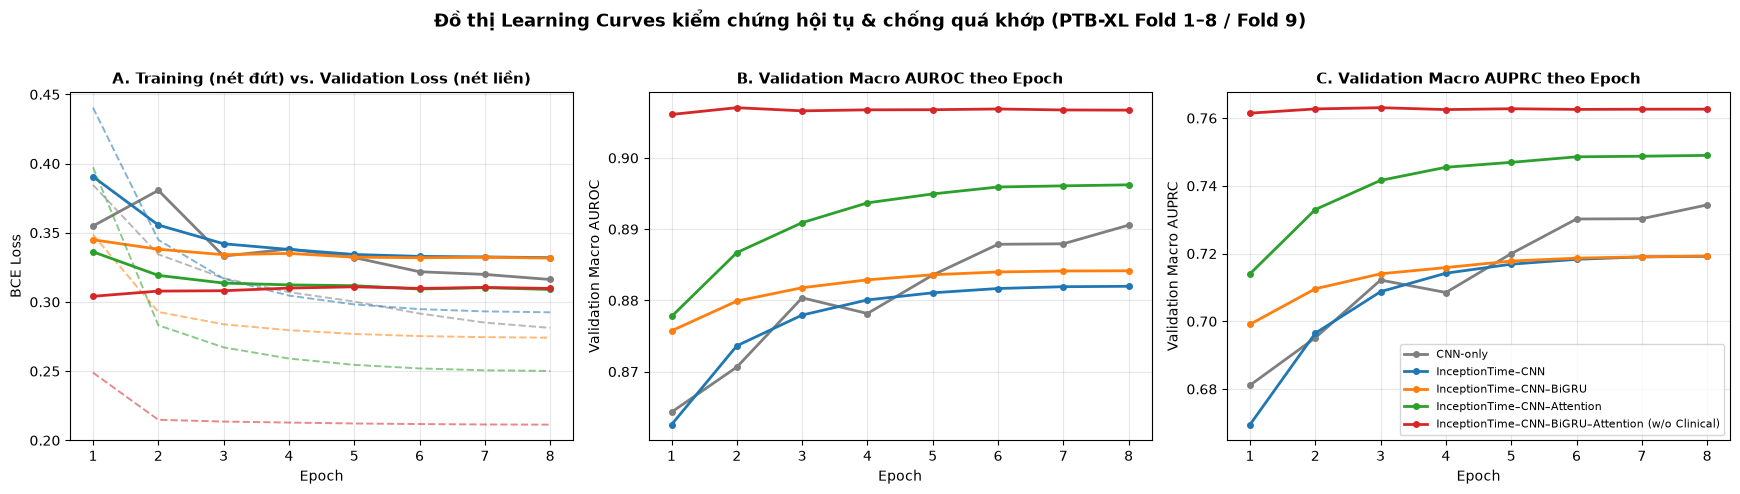

In [16]:
import matplotlib.pyplot as plt
from torch.utils.tensorboard import SummaryWriter

figures_dir = project_root / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
tb_root = project_root / 'runs' / 'ptbxl_m3'
tb_root.mkdir(parents=True, exist_ok=True)

curve_variants = [
    ('cnn_only', 'CNN-only', '#7f7f7f'),
    ('inception_cnn', 'InceptionTime–CNN', '#1f77b4'),
    ('inception_cnn_bigru', 'InceptionTime–CNN–BiGRU', '#ff7f0e'),
    ('inception_cnn_attention', 'InceptionTime–CNN–Attention', '#2ca02c'),
    ('inception_cnn_bigru_attention', 'InceptionTime–CNN–BiGRU–Attention (w/o Clinical)', '#d62728'),
]

logged_runs = 0
for key, short_name, _ in curve_variants:
    hist = ablation_registry.get(key, {}).get('history', [])
    if not hist:
        continue
    writer = SummaryWriter(log_dir=str(tb_root / key))
    for h in hist:
        ep = int(h['epoch'])
        writer.add_scalar('Loss/train', float(h['train_loss']), ep)
        writer.add_scalar('Loss/val', float(h['val_loss']), ep)
        writer.add_scalar('Metrics/val_macro_auroc', float(h['val_macro_auroc']), ep)
        writer.add_scalar('Metrics/val_macro_auprc', float(h['val_macro_auprc']), ep)
    writer.close()
    logged_runs += 1

print(f'Đã ghi log TensorBoard cho {logged_runs} cấu hình vào: {tb_root}')
print('Mở giao diện theo dõi trực quan bằng lệnh: tensorboard --logdir runs/ptbxl_m3')

fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.8))
ax_loss, ax_auroc, ax_auprc = axes[0], axes[1], axes[2]

for key, short_name, color in curve_variants:
    hist = ablation_registry.get(key, {}).get('history', [])
    if not hist:
        continue
    epochs_x = [h['epoch'] for h in hist]
    ax_loss.plot(epochs_x, [h['train_loss'] for h in hist], linestyle='--', color=color, alpha=0.55, lw=1.4)
    ax_loss.plot(epochs_x, [h['val_loss'] for h in hist], marker='o', markersize=4, color=color, lw=2.0, label=short_name)
    ax_auroc.plot(epochs_x, [h['val_macro_auroc'] for h in hist], marker='o', markersize=4, color=color, lw=2.0, label=short_name)
    ax_auprc.plot(epochs_x, [h['val_macro_auprc'] for h in hist], marker='o', markersize=4, color=color, lw=2.0, label=short_name)

ax_loss.set_title('A. Training (nét đứt) vs. Validation Loss (nét liền)', fontsize=11, fontweight='bold')
ax_loss.set_xlabel('Epoch')
ax_loss.set_ylabel('BCE Loss')
ax_loss.grid(True, alpha=0.3)

ax_auroc.set_title('B. Validation Macro AUROC theo Epoch', fontsize=11, fontweight='bold')
ax_auroc.set_xlabel('Epoch')
ax_auroc.set_ylabel('Validation Macro AUROC')
ax_auroc.grid(True, alpha=0.3)

ax_auprc.set_title('C. Validation Macro AUPRC theo Epoch', fontsize=11, fontweight='bold')
ax_auprc.set_xlabel('Epoch')
ax_auprc.set_ylabel('Validation Macro AUPRC')
ax_auprc.grid(True, alpha=0.3)
ax_auprc.legend(loc='lower right', fontsize=8.2, frameon=True)

fig.suptitle('Đồ thị Learning Curves kiểm chứng hội tụ & chống quá khớp (PTB-XL Fold 1–8 / Fold 9)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
lc_path = figures_dir / 'training_learning_curves.png'
fig.savefig(lc_path, bbox_inches='tight', dpi=200)
plt.show()
print('Saved figure:', lc_path)

### 10.2. Biểu đồ cột so sánh tổng hợp Baselines (Mốc 2), Ablation Variants & Mô hình Đề xuất (Mốc 3)

Đặt trực quan toàn bộ tiến trình hiệu năng trên tập Test (`Fold 10`, `n = 2.150`) từ `Baseline 1 (LogReg)` → `Baseline 2 (ResNet1D)` → các biến thể `Exact-Parent Ablation` → `Mô hình Đề xuất Đầy đủ`.

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\ablation_architecture_comparison.png


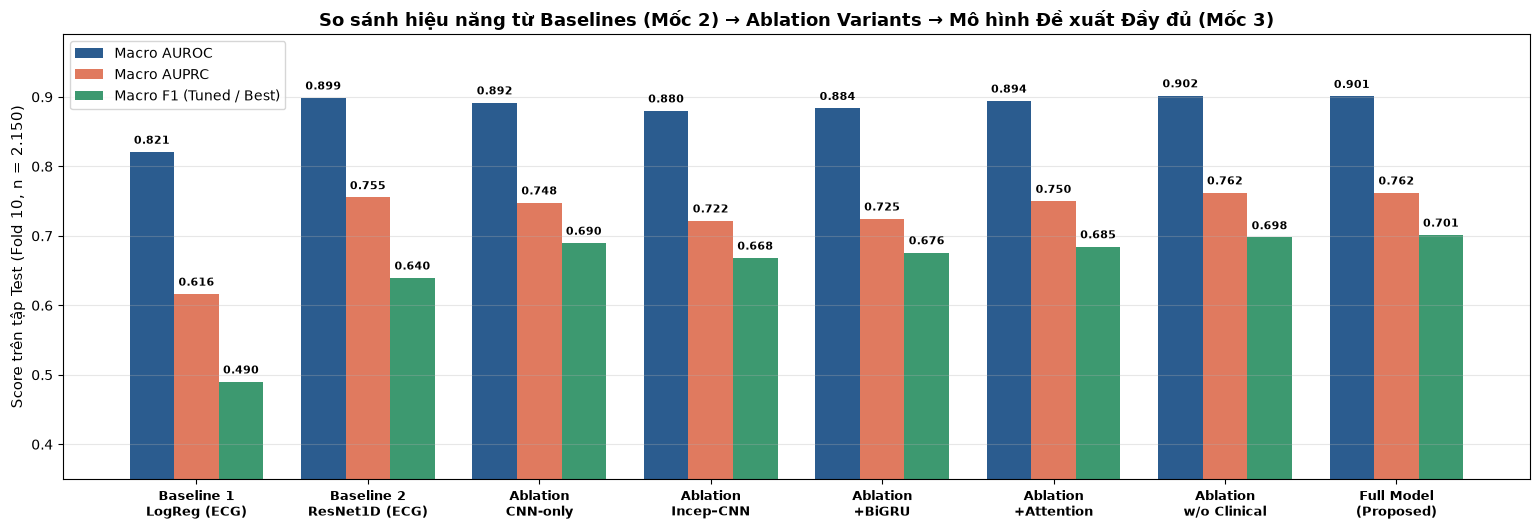

In [17]:
comp_names = [
    'Baseline 1\nLogReg (ECG)',
    'Baseline 2\nResNet1D (ECG)',
    'Ablation\nCNN-only',
    'Ablation\nIncep–CNN',
    'Ablation\n+BiGRU',
    'Ablation\n+Attention',
    'Ablation\nw/o Clinical',
    'Full Model\n(Proposed)',
]
comp_auroc = [
    b1_test_metrics['macro_auroc'],
    b2_test_metrics['macro_auroc'],
    ablation_registry['cnn_only']['test_at_tuned']['macro_auroc'],
    ablation_registry['inception_cnn']['test_at_tuned']['macro_auroc'],
    ablation_registry['inception_cnn_bigru']['test_at_tuned']['macro_auroc'],
    ablation_registry['inception_cnn_attention']['test_at_tuned']['macro_auroc'],
    ablation_registry['inception_cnn_bigru_attention']['test_at_tuned']['macro_auroc'],
    ablation_registry['full_model']['test_at_tuned']['macro_auroc'],
]
comp_auprc = [
    b1_test_metrics['macro_auprc'],
    b2_test_metrics['macro_auprc'],
    ablation_registry['cnn_only']['test_at_tuned']['macro_auprc'],
    ablation_registry['inception_cnn']['test_at_tuned']['macro_auprc'],
    ablation_registry['inception_cnn_bigru']['test_at_tuned']['macro_auprc'],
    ablation_registry['inception_cnn_attention']['test_at_tuned']['macro_auprc'],
    ablation_registry['inception_cnn_bigru_attention']['test_at_tuned']['macro_auprc'],
    ablation_registry['full_model']['test_at_tuned']['macro_auprc'],
]
comp_f1 = [
    b1_test_metrics['macro_f1'],
    b2_test_metrics['macro_f1'],
    ablation_registry['cnn_only']['test_at_tuned']['macro_f1'],
    ablation_registry['inception_cnn']['test_at_tuned']['macro_f1'],
    ablation_registry['inception_cnn_bigru']['test_at_tuned']['macro_f1'],
    ablation_registry['inception_cnn_attention']['test_at_tuned']['macro_f1'],
    ablation_registry['inception_cnn_bigru_attention']['test_at_tuned']['macro_f1'],
    ablation_registry['full_model']['test_at_tuned']['macro_f1'],
]

x_idx = np.arange(len(comp_names))
width = 0.26
fig, ax = plt.subplots(figsize=(15.5, 5.4))
b_roc = ax.bar(x_idx - width, comp_auroc, width, label='Macro AUROC', color='#2b5c8f')
b_prc = ax.bar(x_idx, comp_auprc, width, label='Macro AUPRC', color='#e07a5f')
b_f1 = ax.bar(x_idx + width, comp_f1, width, label='Macro F1 (Tuned / Best)', color='#3d9970')

for bars in (b_roc, b_prc, b_f1):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.008, f'{h:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xticks(x_idx)
ax.set_xticklabels(comp_names, fontsize=9.2, fontweight='bold')
ax.set_ylim(0.35, 0.99)
ax.set_ylabel('Score trên tập Test (Fold 10, n = 2.150)', fontsize=11)
ax.set_title('So sánh hiệu năng từ Baselines (Mốc 2) → Ablation Variants → Mô hình Đề xuất Đầy đủ (Mốc 3)', fontsize=13, fontweight='bold')
ax.legend(loc='upper left', frameon=True, fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
comp_path = figures_dir / 'ablation_architecture_comparison.png'
fig.savefig(comp_path, bbox_inches='tight', dpi=200)
plt.show()
print('Saved figure:', comp_path)